# HOD mock generation benchmarks

Plot the saved timing dictionaries in this directory, without running new simulations.
The fixed-density comparison uses the requested SHOD density
$\bar n_{\rm gal}=7\times10^{-4}\,(h\,{\rm Mpc}^{-1})^3$.
Times are in seconds. Abacus uses particles and Uchuu uses subhalos for the `part` files.

Run all cells again after updating the `.npy` files. Figures and timing tables are exported
under `plots/`; plots are also embedded in this notebook.
The files contain one saved timing per point, with no repeat-level uncertainty or run metadata.
The density-scan filename does not specify its satellite prescription.


In [1]:
%matplotlib inline
from pathlib import Path
from collections.abc import Mapping

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter
from IPython.display import Markdown, display

# Works when launched from this directory, the repository root, or its parent.
candidates = [Path.cwd(), Path.cwd() / 'checks_pipeline' / 'benchmark',
              Path.cwd() / 'HODDIES' / 'checks_pipeline' / 'benchmark']
DATA_DIR = next((p for p in candidates if (p / 'time_results_nfw_Uchuu.npy').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the directory containing the benchmark .npy files.')
DATA_DIR = DATA_DIR.resolve()
EXPORT_DIR = DATA_DIR / 'plots'
EXPORT_DIR.mkdir(exist_ok=True)

FIXED_DENSITY = 7e-4  # Requested benchmark density; not stored in the timing dictionaries.
REFERENCE_THREADS = 32
DENSITY_PROFILE_LABEL = 'Satellite prescription unspecified'
SHOW_ENDPOINT_GUIDES = False  # Optional measured NFW endpoint guides; these are not fitted floors.

BOXES = {
    'abacus_base': {'label': r'Abacus base: $2\,h^{-1}\,\mathrm{Gpc}$',
                    'file_label': 'abcus_base', 'color': 'tab:blue'},
    'abacus_highbase': {'label': r'Abacus highbase: $1\,h^{-1}\,\mathrm{Gpc}$',
                        'file_label': 'abcus_highbase', 'color': 'tab:red'},
    'uchuu': {'label': r'Uchuu: $2\,h^{-1}\,\mathrm{Gpc}$',
              'file_label': 'Uchuu', 'color': 'tab:green'},
}
PROFILES = {'part': {'label': 'Particles / subhalos', 'marker': 'o'},
            'nfw': {'label': 'NFW profile', 'marker': 'd'}}

plt.rcParams.update({'font.size': 12, 'axes.labelsize': 13, 'axes.titlesize': 13,
                     'legend.fontsize': 10, 'figure.dpi': 110, 'savefig.dpi': 200})
print(f'Timing files: {DATA_DIR}')


Timing files: /global/u1/a/arocher/Code/postdoc/HODDIES_v2/HODDIES/checks_pipeline/benchmark


## Load the timing dictionaries

Fixed-density files map `nthreads -> seconds`. The density file maps
`nthreads -> {density: seconds}`. Numeric keys are sorted before plotting.
If future files contain repeated timings per point, use their median and show their
25th–75th percentile range. Scalar timings have no error bars.


In [2]:
def load_mapping(filename):
    # These local NumPy files contain pickled Python dictionaries.
    data = np.load(DATA_DIR / filename, allow_pickle=True).item()
    if not isinstance(data, Mapping) or not data:
        raise ValueError(f'{filename}: expected a nonempty dictionary.')
    return data


def timing_summary(value):
    samples = np.asarray(value, dtype=float).reshape(-1)
    if not samples.size or not np.all(np.isfinite(samples) & (samples > 0)):
        raise ValueError(f'Expected positive, finite timings, got {value!r}')
    return {'seconds': float(np.median(samples)), 'q25': float(np.quantile(samples, .25)),
            'q75': float(np.quantile(samples, .75)), 'samples': len(samples)}


def thread_count(value):
    numeric = float(value)
    if not np.isfinite(numeric) or numeric < 1 or not numeric.is_integer():
        raise ValueError(f'Invalid thread count: {value!r}')
    return int(numeric)


fixed_records = []
for box, info in BOXES.items():
    for profile in PROFILES:
        filename = f'time_results_{profile}_{info["file_label"]}.npy'
        for threads, value in load_mapping(filename).items():
            fixed_records.append({'box': box, 'profile': profile,
                                  'nthreads': thread_count(threads), 'density': FIXED_DENSITY,
                                  'source_file': filename, **timing_summary(value)})
fixed = pd.DataFrame(fixed_records).sort_values(['box', 'profile', 'nthreads']).reset_index(drop=True)
if fixed.duplicated(['box', 'profile', 'nthreads']).any():
    raise ValueError('Duplicate thread counts after converting keys to integers.')

filename = 'time_results_abcus_base_dens.npy'
density_records = []
for threads, scan in load_mapping(filename).items():
    if not isinstance(scan, Mapping) or not scan:
        raise ValueError(f'{filename}: expected a nonempty density dictionary for {threads}.')
    for density, value in scan.items():
        density = float(density)
        if not np.isfinite(density) or density <= 0:
            raise ValueError(f'Invalid density: {density!r}')
        density_records.append({'box': 'abacus_base', 'nthreads': thread_count(threads),
                                'density': density, 'source_file': filename,
                                **timing_summary(value)})
density_scan = pd.DataFrame(density_records).sort_values(['nthreads', 'density']).reset_index(drop=True)
if density_scan.duplicated(['nthreads', 'density']).any():
    raise ValueError('Duplicate density-scan points after converting keys to numbers.')

print(f'Loaded {len(fixed)} fixed-density points and {len(density_scan)} density-scan points.')
for box, group in fixed.groupby('box'):
    comparison = group.pivot(index='nthreads', columns='profile', values='seconds')
    if {'part', 'nfw'} <= set(comparison.columns) and comparison.notna().all().all():
        if np.array_equal(comparison['part'].to_numpy(), comparison['nfw'].to_numpy()):
            display(Markdown(f'**Saved-data note:** `{box}` has identical particle and NFW timings '
                             'at every thread count. Those curves overlap in the plot.'))


Loaded 42 fixed-density points and 35 density-scan points.


**Saved-data note:** `abacus_base` has identical particle and NFW timings at every thread count. Those curves overlap in the plot.

In [3]:
fixed_table = fixed.pivot(index='nthreads', columns=['box', 'profile'], values='seconds')
fixed_table = fixed_table.reindex(columns=pd.MultiIndex.from_product([BOXES, PROFILES]))
display(Markdown('**Fixed-density timing table [s]**'))
display(fixed_table.style.format('{:.3f}'))
display(Markdown('**Abacus base density-scan timing table [s]**'))
density_table = density_scan.pivot(index='density', columns='nthreads', values='seconds')
display(density_table.style.format('{:.3f}'))


**Fixed-density timing table [s]**

**Abacus base density-scan timing table [s]**

nthreads,4,8,16,32,64,128,256
density,,,,,,,
0.000100,10.121,7.009,4.515,3.605,2.961,2.721,2.782
0.000500,11.168,6.873,5.291,4.332,3.789,3.455,3.378
0.001000,11.776,7.791,5.847,4.876,4.342,4.144,4.074
0.005000,14.890,10.875,9.286,7.817,7.507,7.134,7.036
0.010000,17.933,13.689,11.936,10.939,10.268,9.997,9.915


In [4]:
def plot_timings(ax, frame, x, *, color, marker, label=None):
    frame = frame.sort_values(x)
    # Hollow NFW diamonds keep both symbols visible when particle and NFW data overlap.
    line, = ax.plot(frame[x], frame['seconds'], color=color, marker=marker,
                    markerfacecolor='white' if marker == 'd' else color,
                    markersize=6, linewidth=1.6, linestyle='--', label=label)
    if (frame['samples'] > 1).any():
        ax.fill_between(frame[x].to_numpy(), frame['q25'].to_numpy(),
                        frame['q75'].to_numpy(), color=color, alpha=.12)
    return line


def style_axes(ax, xlabel):
    ax.set(xscale='log', yscale='log', xlabel=xlabel, ylabel='Mock generation time (s)')
    ax.grid(axis='y', which='major', alpha=.3)
    ax.tick_params(which='both', direction='in', top=True, right=True)


def save_figure(fig, name):
    for suffix in ('png', 'pdf'):
        fig.savefig(EXPORT_DIR / f'{name}.{suffix}', bbox_inches='tight')


## Time versus number of threads

Colors distinguish the three simulation boxes; circles indicate particles/subhalos and
hollow diamonds indicate NFW sampling. The vertical guide marks 32 threads.
The Abacus base curves overlap because their saved timing values are identical.


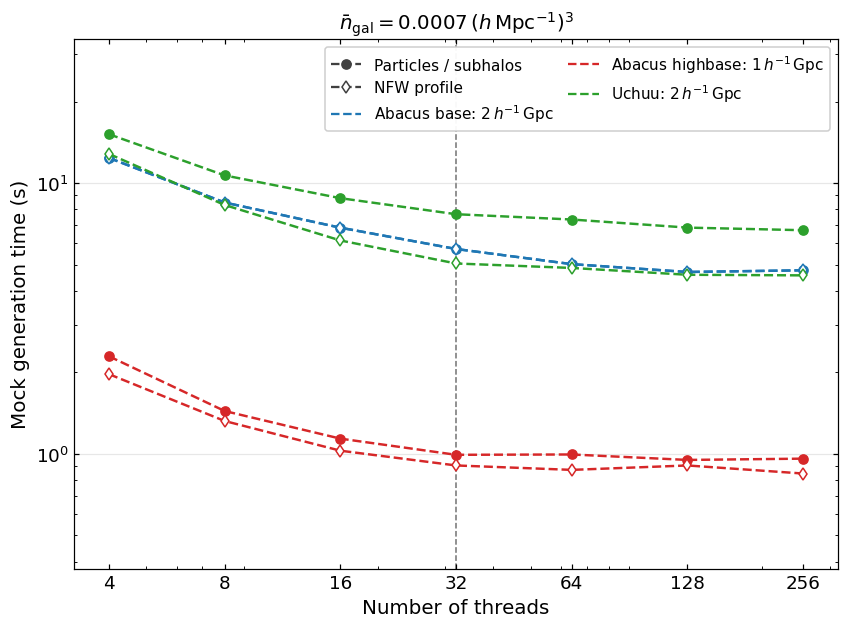

In [5]:
fig, ax = plt.subplots(figsize=(7.6, 5.6), layout='constrained')
for box, info in BOXES.items():
    for profile, style in PROFILES.items():
        subset = fixed[(fixed['box'] == box) & (fixed['profile'] == profile)]
        plot_timings(ax, subset, 'nthreads', color=info['color'], marker=style['marker'])
    if SHOW_ENDPOINT_GUIDES:
        endpoint = fixed[(fixed['box'] == box) & (fixed['profile'] == 'nfw')].sort_values('nthreads').iloc[-1]
        ax.axhline(endpoint['seconds'], color=info['color'], ls=':', alpha=.5, lw=1)

threads = np.sort(fixed['nthreads'].unique())
if threads.min() <= REFERENCE_THREADS <= threads.max():
    ax.axvline(REFERENCE_THREADS, color='black', linestyle='--', linewidth=1, alpha=.55, zorder=0)
style_axes(ax, 'Number of threads')
ax.set_xticks(threads)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set_title(r'$\bar n_{\rm gal} = %g\,(h\,\mathrm{Mpc}^{-1})^3$' % FIXED_DENSITY)

handles = [Line2D([], [], color='0.25', marker=s['marker'], linestyle='--',
                  markerfacecolor='white' if p == 'nfw' else '0.25', label=s['label'])
           for p, s in PROFILES.items()]
handles += [Line2D([], [], color=b['color'], linestyle='--', label=b['label']) for b in BOXES.values()]
ax.legend(handles=handles, loc='upper right', ncol=2, framealpha=.95, columnspacing=1)
ax.margins(y=.28)
save_figure(fig, 'thread_scaling')
plt.show()


## Time versus galaxy density: all thread counts

The nested dictionary provides an Abacus base density scan from $10^{-4}$ to
$10^{-2}\,(h\,{\rm Mpc}^{-1})^3$. Each curve uses a different number of threads.
The satellite prescription is left unspecified because it is not recorded in the file.


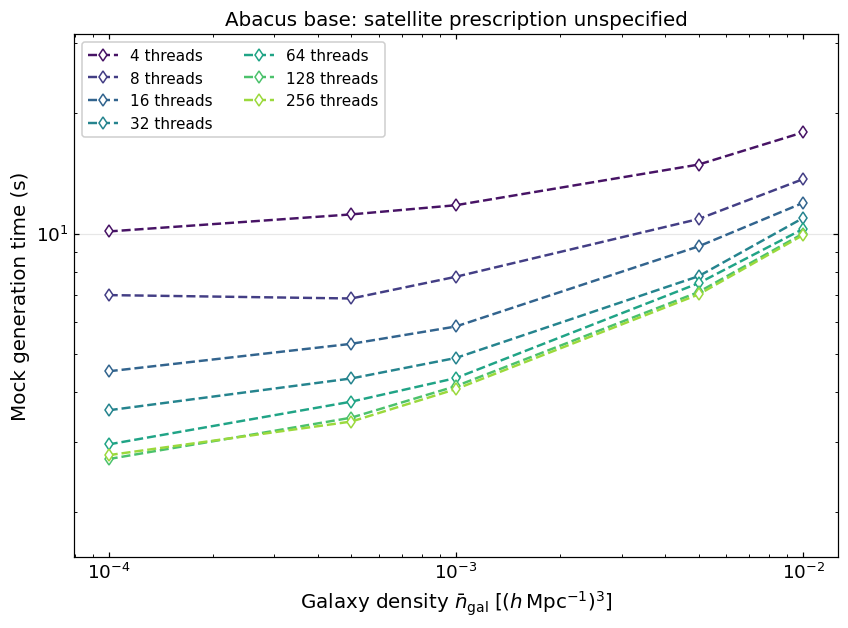

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 5.6), layout='constrained')
density_threads = np.sort(density_scan['nthreads'].unique())
colors = plt.cm.viridis(np.linspace(.05, .85, len(density_threads)))
for threads, color in zip(density_threads, colors):
    subset = density_scan[density_scan['nthreads'] == threads]
    plot_timings(ax, subset, 'density', color=color, marker='d', label=f'{threads} threads')
style_axes(ax, r'Galaxy density $\bar n_{\rm gal}\;[(h\,\mathrm{Mpc}^{-1})^3]$')
ax.set_title('Abacus base: ' + DENSITY_PROFILE_LABEL.lower())
ax.legend(ncol=2, loc='upper left', framealpha=.95)
ax.margins(y=.3)
save_figure(fig, 'density_scaling_all_threads')
plt.show()


## Density scan at 32 threads

A single-thread-count view follows the second reference plot. Change `REFERENCE_THREADS`
in the configuration cell to show another measured thread count.


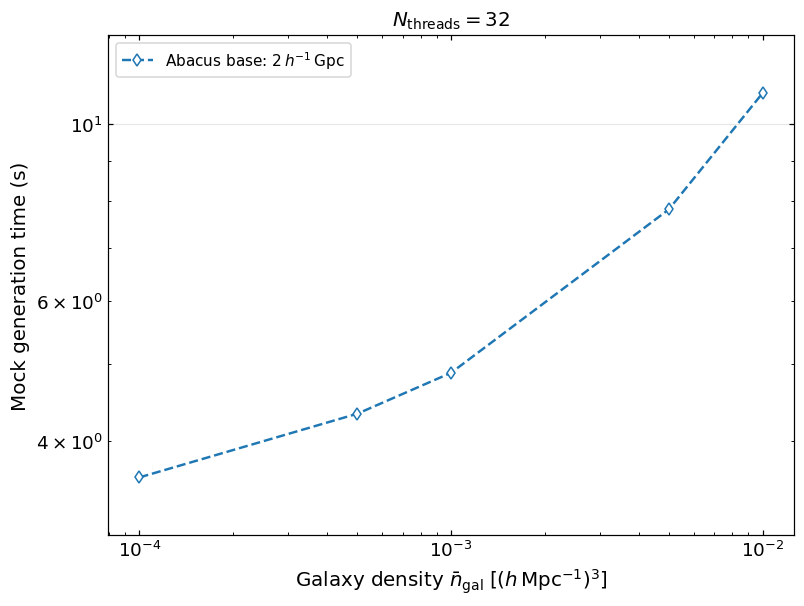

In [7]:
selected = density_scan[density_scan['nthreads'] == REFERENCE_THREADS]
if selected.empty:
    print(f'No density scan at {REFERENCE_THREADS} threads; available: {density_threads.tolist()}')
else:
    fig, ax = plt.subplots(figsize=(7.2, 5.4), layout='constrained')
    plot_timings(ax, selected, 'density', color=BOXES['abacus_base']['color'], marker='d',
                 label=BOXES['abacus_base']['label'])
    style_axes(ax, r'Galaxy density $\bar n_{\rm gal}\;[(h\,\mathrm{Mpc}^{-1})^3]$')
    ax.set_title(r'$N_{\rm threads} = %d$' % REFERENCE_THREADS)
    ax.legend(loc='upper left')
    ax.margins(y=.15)
    save_figure(fig, f'density_scaling_{REFERENCE_THREADS}_threads')
    plt.show()


## Export the numbers

Long-format CSV files preserve source filenames, numerical thread counts and densities,
timing summaries, and sample counts. The two timing matrices match the displayed tables.
The fixed density is the requested benchmark setting, not metadata recovered from the files.
Rerunning this notebook refreshes its plots and exported tables from the current `.npy` files.


In [8]:
fixed.to_csv(EXPORT_DIR / 'fixed_density_timings.csv', index=False)
density_scan.to_csv(EXPORT_DIR / 'density_scan_timings.csv', index=False)
fixed_table.to_csv(EXPORT_DIR / 'fixed_density_timing_matrix.csv')
density_table.to_csv(EXPORT_DIR / 'density_timing_matrix.csv')
print(f'Exports: {EXPORT_DIR}')
for path in sorted(EXPORT_DIR.iterdir()):
    if path.suffix in {'.png', '.pdf', '.csv'}:
        print(f'  {path.name}')


Exports: /global/u1/a/arocher/Code/postdoc/HODDIES_v2/HODDIES/checks_pipeline/benchmark/plots
  density_scaling_32_threads.pdf
  density_scaling_32_threads.png
  density_scaling_all_threads.pdf
  density_scaling_all_threads.png
  density_scan_timings.csv
  density_timing_matrix.csv
  fixed_density_timing_matrix.csv
  fixed_density_timings.csv
  thread_scaling.pdf
  thread_scaling.png


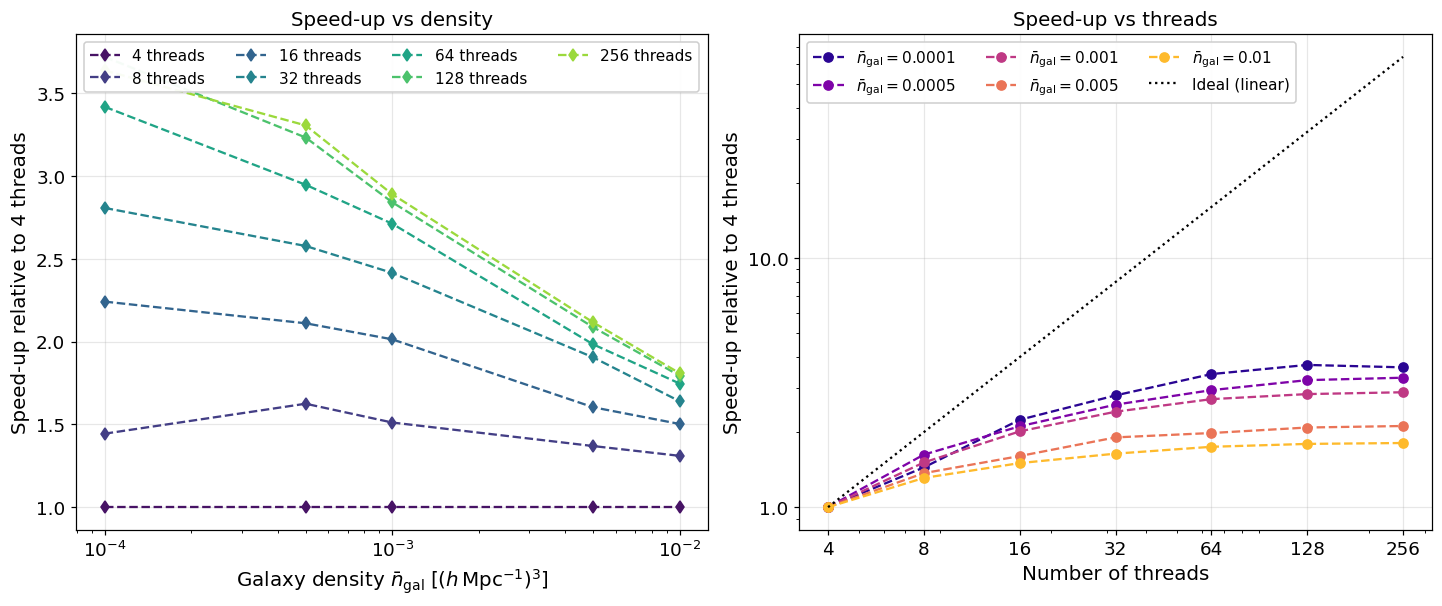

**Parallel efficiency (speed-up / ideal)**

nthreads,4,8,16,32,64,128,256
density,,,,,,,
0.000100,1.00,0.72,0.56,0.35,0.21,0.12,0.06
0.000500,1.00,0.81,0.53,0.32,0.18,0.10,0.05
0.001000,1.00,0.76,0.50,0.30,0.17,0.09,0.05
0.005000,1.00,0.68,0.40,0.24,0.12,0.07,0.03
0.010000,1.00,0.66,0.38,0.20,0.11,0.06,0.03


In [8]:
# Speed-up relative to the 4-thread run, as a function of density
BASE_THREADS = 4
base = density_scan[density_scan['nthreads'] == BASE_THREADS].set_index('density')['seconds']
speedup = density_scan.assign(
    speedup=lambda d: d['density'].map(base) / d['seconds'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), layout='constrained')

# Left: speed-up vs density, one curve per thread count
ax = axes[0]
for threads, color in zip(density_threads, colors):
    sub = speedup[speedup['nthreads'] == threads].sort_values('density')
    ax.plot(sub['density'], sub['speedup'], color=color, marker='d',
            linestyle='--', label=f'{threads} threads')
ax.set(xscale='log', yscale='linear',
       xlabel=r'Galaxy density $\bar n_{\rm gal}\;[(h\,\mathrm{Mpc}^{-1})^3]$',
       ylabel=f'Speed-up relative to {BASE_THREADS} threads')
ax.set_title('Speed-up vs density')
ax.grid(alpha=.3)
ax.legend(ncol=4, loc='upper left', framealpha=.95)

# Right: speed-up vs threads, one curve per density, with ideal linear scaling
ax = axes[1]
dens_values = np.sort(speedup['density'].unique())
dcolors = plt.cm.plasma(np.linspace(.05, .85, len(dens_values)))
for dens, color in zip(dens_values, dcolors):
    sub = speedup[speedup['density'] == dens].sort_values('nthreads')
    ax.plot(sub['nthreads'], sub['speedup'], color=color, marker='o',
            linestyle='--', label=rf'$\bar n_{{\rm gal}}={dens:g}$')
ideal = density_threads / BASE_THREADS
ax.plot(density_threads, ideal, color='black', linestyle=':', label='Ideal (linear)')
ax.set(xscale='log', yscale='log', xlabel='Number of threads',
       ylabel=f'Speed-up relative to {BASE_THREADS} threads')
ax.set_xticks(density_threads)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.set_title('Speed-up vs threads')
ax.grid(alpha=.3)
ax.legend(loc='upper left', framealpha=.95, ncol=3)

save_figure(fig, 'speedup_vs_density_threads')
plt.show()

# Parallel efficiency table: speed-up / ideal speed-up
efficiency = speedup.assign(efficiency=lambda d: d['speedup'] * BASE_THREADS / d['nthreads']) \
                    .pivot(index='density', columns='nthreads', values='efficiency')
display(Markdown('**Parallel efficiency (speed-up / ideal)**'))
display(efficiency.style.format('{:.2f}'))


In [ ]:
nlogn_reference = (
    density_threads * np.log(density_threads)
    / (BASE_THREADS * np.log(BASE_THREADS))
)
ax.plot(density_threads, nlogn_reference, color='tab:orange', linestyle='-.',
        label=r'$N\log N$ reference')